# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [3]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [4]:
df = pd.read_csv("data/AviationData_cleaned.csv", encoding="utf-8")

print("Shape:", df.shape)
display(df.head())

Shape: (21429, 28)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Injury.Severity,Aircraft.damage,Aircraft.Category,Registration.Number,...,Total.Uninjured,Weather.Condition,Publication.Date,Total.Occupants.Reported,Fatal.Serious.Injuries.Count,Fatal.Serious.Injury.Fraction,Aircraft.Destroyed,Make.Clean,Model.Clean,Plane.Type
0,20001214X42478,Incident,LAX83IA149B,1983-03-18,"LOS ANGELES, CA",United States,Incident,Minor,Airplane,N323EA,...,588.0,VMC,04-12-2014,NaN,NaN,NaN,False,LOCKHEED,L-1011,LOCKHEED | L-1011
1,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,Incident,Minor,Airplane,9VSQQ,...,588.0,VMC,04-12-2014,NaN,NaN,NaN,False,BOEING,747,BOEING | 747
2,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,Fatal(1),Destroyed,Airplane,N9600W,...,NaN,IMC,02-05-2011,NaN,2.0,NaN,True,PIPER,PA-28-140,PIPER | PA-28-140
3,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,Fatal(1),NaN,Airplane,N927BA,...,4.0,VMC,17-10-2016,NaN,NaN,NaN,NaN,DE HAVILLAND,DHC-6,DE HAVILLAND | DHC-6
4,20001214X44248,Incident,MIA83IA210,1983-08-21,"NORFOLK, VA",United States,Incident,Minor,Airplane,N69NA,...,289.0,VMC,01-02-2016,NaN,NaN,NaN,False,DOUGLAS,DC-10-10,DOUGLAS | DC-10-10


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [5]:
df["Plane.Size"] = pd.Series(pd.NA, index=df.index, dtype="string")
df.loc[df["Total.Occupants.Reported"].between(1, 19), "Plane.Size"] = "Small"
df.loc[df["Total.Occupants.Reported"].ge(20), "Plane.Size"] = "Large"

display(df["Plane.Size"].value_counts(dropna=False))

Plane.Size
Small    16689
<NA>      3874
Large      866
Name: count, dtype: Int64

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [6]:
valid_make_events = df.dropna(
    subset=["Make.Clean", "Plane.Size", "Fatal.Serious.Injury.Fraction"]
)

for size in ["Small", "Large"]:
    counts = (
        valid_make_events.loc[valid_make_events["Plane.Size"].eq(size)]
        .groupby("Make.Clean")["Fatal.Serious.Injury.Fraction"]
        .count()
        .sort_values(ascending=False)
    )

    print(f"\n{size}: makes with at least 50 usable records:",
          (counts >= 50).sum())
    display(counts.head(20))


Small: makes with at least 50 usable records: 28


Make.Clean
CESSNA                5814
PIPER                 3395
BEECH                 1233
MOONEY                 300
BOEING                 232
CIRRUS DESIGN CORP     219
AIR TRACTOR INC        218
BELLANCA               177
MAULE                  171
AERONCA                168
AIR TRACTOR            160
CHAMPION               132
CIRRUS                 127
LUSCOMBE               115
STINSON                112
GRUMMAN                108
NORTH AMERICAN          99
DEHAVILLAND             92
AVIAT AIRCRAFT INC      76
AERO COMMANDER          75
Name: Fatal.Serious.Injury.Fraction, dtype: int64


Large: makes with at least 50 usable records: 3


Make.Clean
BOEING                           486
AIRBUS                           114
EMBRAER                           73
BOMBARDIER INC                    44
MCDONNELL DOUGLAS                 33
AIRBUS INDUSTRIE                  27
BOMBARDIER                        19
SAAB                               7
ATR                                6
MCDONNELL DOUGLAS AIRCRAFT CO      6
EMBRAER S A                        5
DOUGLAS                            5
BAE                                4
BOMBARDIER, INC.                   4
FOKKER                             3
DE HAVILLAND                       3
EMBRAER-EMPRESA BRASILEIRA DE      3
SUKHOI                             2
737                                2
DEHAVILLAND                        2
Name: Fatal.Serious.Injury.Fraction, dtype: int64

In [7]:
valid_make_events = df.dropna(
    subset=["Plane.Size", "Make.Clean", "Fatal.Serious.Injury.Fraction"]
)

make_stats = (
    valid_make_events
    .groupby(["Plane.Size", "Make.Clean"])
    .agg(
        n=("Fatal.Serious.Injury.Fraction", "count"),
        mean_fraction=("Fatal.Serious.Injury.Fraction", "mean")
    )
    .reset_index()
)

small_candidates = make_stats.loc[
    (make_stats["Plane.Size"] == "Small") &
    (make_stats["n"] >= 50)
].copy()
small_top15 = small_candidates.nsmallest(15, "mean_fraction")

large_all = make_stats.loc[
    make_stats["Plane.Size"] == "Large"
].copy()
large_top15 = large_all.nsmallest(15, "mean_fraction").copy()
large_top15["Meets 50-record threshold"] = large_top15["n"] >= 50

large_robust = large_all.loc[large_all["n"] >= 50].sort_values(
    "mean_fraction"
)

print("Top 15 Small makes (all meet n >= 50):")
display(small_top15[["Make.Clean", "n", "mean_fraction"]])

print("Top 15 Large makes (under-threshold entries are exploratory):")
display(large_top15[
    ["Make.Clean", "n", "mean_fraction", "Meets 50-record threshold"]
])

print("Large makes meeting n >= 50:")
display(large_robust[["Make.Clean", "n", "mean_fraction"]])

Top 15 Small makes (all meet n >= 50):


,Make.Clean,n,mean_fraction
187,BOEING,232,0.156968
135,AVIAT AIRCRAFT INC,76,0.164474
639,MAULE,171,0.192593
482,GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.206897
342,DIAMOND AIRCRAFT IND INC,74,0.222973
333,DEHAVILLAND,92,0.234170
833,ROCKWELL INTERNATIONAL,54,0.236111
54,AERONCA,168,0.245040
902,STINSON,112,0.249256
179,BELLANCA,177,0.252825


Top 15 Large makes (under-threshold entries are exploratory):


,Make.Clean,n,mean_fraction,Meets 50-record threshold
0,737,2,0.0,False
5,BAE,4,0.0,False
9,BOEING OF CANADA/DEHAV DIV,1,0.0,False
12,"BOMBARDIER, INC.",4,0.0,False
13,CESSNA,2,0.0,False
15,DEHAVILLAND,2,0.0,False
16,DOUGLAS,5,0.0,False
19,EMBRAER S.A.,1,0.0,False
20,EMBRAER-EMPRESA BRASILEIRA DE,3,0.0,False
22,GULFSTREAM,1,0.0,False


Large makes meeting n >= 50:


,Make.Clean,n,mean_fraction
7,BOEING,486,0.051341
17,EMBRAER,73,0.056642
1,AIRBUS,114,0.080503


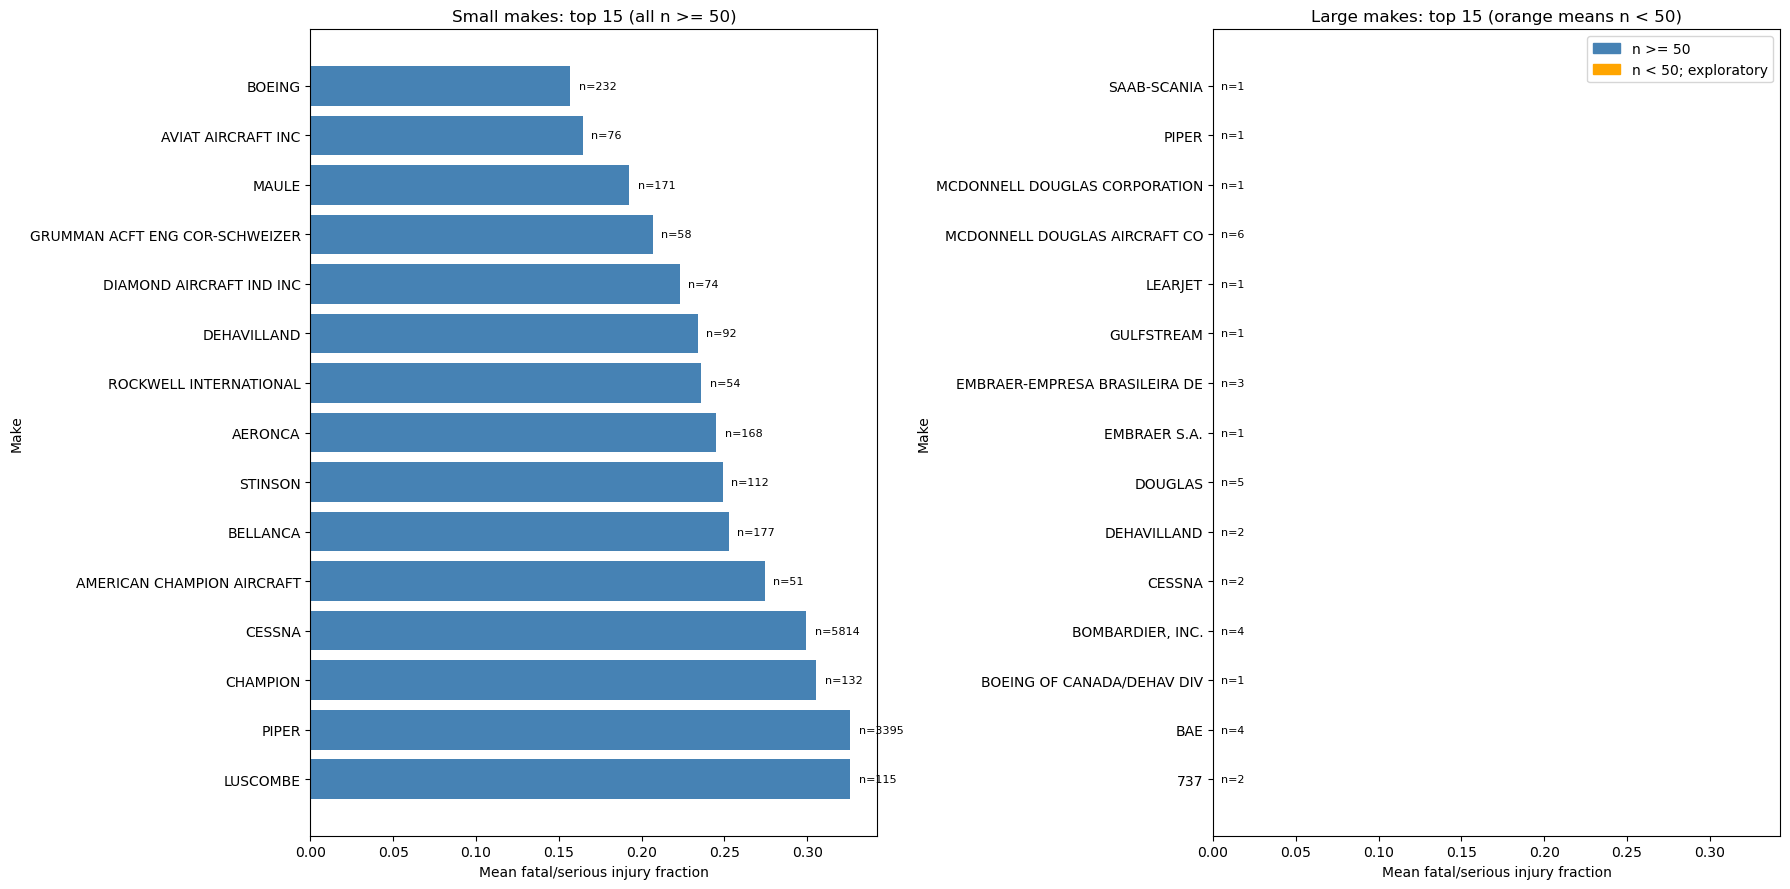

In [8]:
from matplotlib.patches import Patch

small_plot = small_top15.sort_values("mean_fraction", ascending=False)
large_plot = large_top15.sort_values("mean_fraction", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 9), sharex=True)

axes[0].barh(small_plot["Make.Clean"], small_plot["mean_fraction"],
             color="steelblue")
axes[0].set_title("Small makes: top 15 (all n >= 50)")

large_colors = [
    "steelblue" if n >= 50 else "orange"
    for n in large_plot["n"]
]
axes[1].barh(large_plot["Make.Clean"], large_plot["mean_fraction"],
             color=large_colors)
axes[1].set_title("Large makes: top 15 (orange means n < 50)")

for ax, plot_data in zip(axes, [small_plot, large_plot]):
    for bar, n in zip(ax.patches, plot_data["n"]):
        ax.text(
            bar.get_width() + 0.005,
            bar.get_y() + bar.get_height() / 2,
            f"n={n}",
            va="center",
            fontsize=8
        )
    ax.set_xlabel("Mean fatal/serious injury fraction")
    ax.set_ylabel("Make")

axes[1].legend(handles=[
    Patch(color="steelblue", label="n >= 50"),
    Patch(color="orange", label="n < 50; exploratory")
])

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

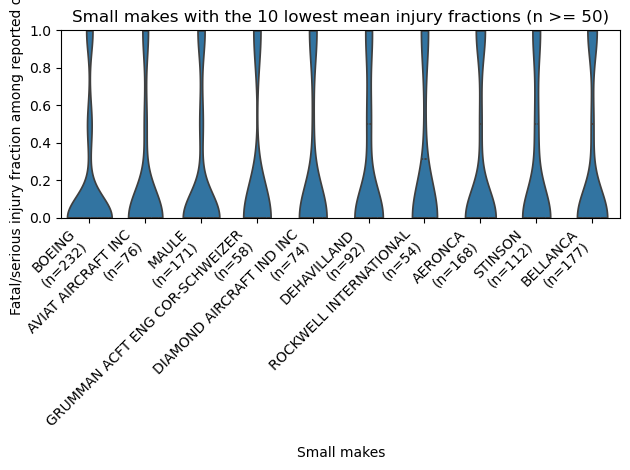

In [9]:
small_top10 = small_candidates.nsmallest(10, "mean_fraction").copy()
small_order = small_top10["Make.Clean"].tolist()

small_violin_data = valid_make_events.loc[
    valid_make_events["Plane.Size"].eq("Small") &
    valid_make_events["Make.Clean"].isin(small_order)
].copy()

ax = sns.violinplot(
    data=small_violin_data,
    x="Make.Clean",
    y="Fatal.Serious.Injury.Fraction",
    order=small_order,
    inner="quartile",
    cut=0
)

n_by_make = small_top10.set_index("Make.Clean")["n"]
ax.set_xticks(
    range(len(small_order)),
    [f"{make}\n(n={n_by_make[make]})" for make in small_order],
    rotation=45,
    ha="right"
)
ax.set_xlabel("Small makes")
ax.set_ylabel("Fatal/serious injury fraction among reported occupants")
ax.set_title("Small makes with the 10 lowest mean injury fractions (n >= 50)")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

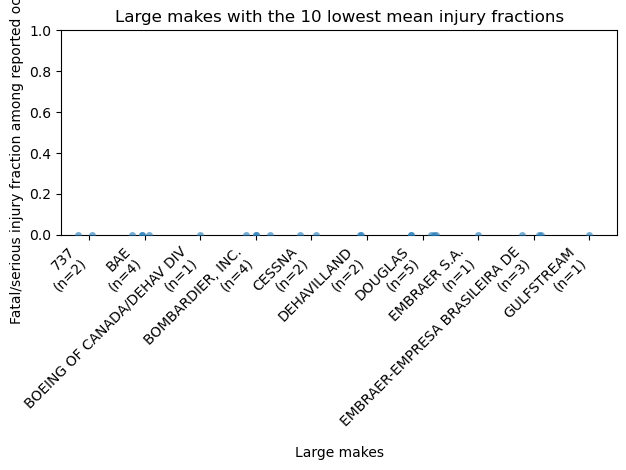

In [10]:
# Show the 10 large makes with the lowest mean injury fractions.
# The n >= 50 threshold leaves only 3 large makes, so the other points
# are exploratory and should not support strong recommendations.

large_top10 = large_all.nsmallest(10, "mean_fraction").copy()
large_order = large_top10["Make.Clean"].tolist()

large_strip_data = valid_make_events.loc[
    valid_make_events["Plane.Size"].eq("Large") &
    valid_make_events["Make.Clean"].isin(large_order)
].copy()

ax = sns.stripplot(
    data=large_strip_data,
    x="Make.Clean",
    y="Fatal.Serious.Injury.Fraction",
    order=large_order,
    jitter=0.25,
    alpha=0.6
)

n_by_make = large_top10.set_index("Make.Clean")["n"]
ax.set_xticks(
    range(len(large_order)),
    [f"{make}\n(n={n_by_make[make]})" for make in large_order],
    rotation=45,
    ha="right"
)

ax.set_xlabel("Large makes")
ax.set_ylabel("Fatal/serious injury fraction among reported occupants")
ax.set_title("Large makes with the 10 lowest mean injury fractions")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [12]:
damage_data = df.dropna(
    subset=["Plane.Size", "Make.Clean", "Aircraft.Destroyed"]
).copy()

# Ensure the destroyed flag is Boolean before calculating its mean.
damage_data["Aircraft.Destroyed"] = (
    damage_data["Aircraft.Destroyed"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"true": 1.0, "false": 0.0})
)

for size in ["Small", "Large"]:
    destruction_stats = (
        damage_data.loc[damage_data["Plane.Size"].eq(size)]
        .groupby("Make.Clean")
        .agg(
            n=("Aircraft.Destroyed", "count"),
            destroyed_fraction=("Aircraft.Destroyed", "mean")
        )
    )

    eligible = destruction_stats.loc[destruction_stats["n"] >= 50]
    lowest_15 = eligible.sort_values("destroyed_fraction").head(15)

    print(f"\n{size} makes with at least 50 known-damage records:")
    print(f"Qualifying makes: {len(eligible)}")
    display(lowest_15)


Small makes with at least 50 known-damage records:
Qualifying makes: 27


,n,destroyed_fraction
Make.Clean,,
GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.017241
LUSCOMBE,112,0.017857
STINSON,112,0.017857
TAYLORCRAFT,73,0.027397
BELLANCA,176,0.034091
AMERICAN CHAMPION AIRCRAFT,50,0.040000
AVIAT AIRCRAFT INC,75,0.040000
MAULE,171,0.040936
AERONCA,168,0.041667



Large makes with at least 50 known-damage records:
Qualifying makes: 2


,n,destroyed_fraction
Make.Clean,,
BOEING,238,0.084034
AIRBUS,50,0.160000


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [ ]:
### Make-level findings

# Among small makes with at least 50 records of known aircraft damage, the lowest recorded destruction fractions were Grumman Acft Eng Cor-Schweizer (58 records; 1.7%), Luscombe (112; 1.8%), and Stinson (112; 1.8%). Cessna had a higher fraction (5,704; 9.7%). These figures describe destruction among recorded accident events; they do not measure the likelihood of an accident or destruction per flight.

# Only two large makes met the 50-record threshold for known damage: Boeing (238 records; 8.4%) and Airbus (50; 16.0%). This is too small a group for a 15-make comparison, and the Airbus estimate is based on the minimum sample size. Treat both as comparisons within this dataset, not as definitive safety rankings.

# A recommendation should consider both these destruction results and the fatal/serious injury fractions. These tables alone do not establish which makes perform best on both measures.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

Small plane types with at least 10 usable records:


,Plane.Type,n,mean_fraction
1764,DIAMOND AIRCRAFT IND INC | DA 20 C1,11,0.000000
478,AIR TRACTOR | AT 602,12,0.041667
1226,CESSNA | 180J,22,0.045455
813,BEECH | B19,14,0.047619
1359,CESSNA | 560XL,21,0.047619
1928,EVEKTOR-AEROTECHNIK AS | SPORTSTAR,20,0.050000
2928,PIPER | PA-20,20,0.050000
1367,CESSNA | A185E,12,0.058333
1337,CESSNA | 402C,16,0.062500
1261,CESSNA | 195,29,0.063218


Large plane types with at least 10 usable records:


,Plane.Type,n,mean_fraction
160,BOEING | 777,31,0.000589
131,BOEING | 757,17,0.001560
174,BOEING | 787,11,0.003058
108,BOEING | 737-7H4,11,0.003537
195,BOMBARDIER INC | CL-600-2B19,15,0.004136
251,EMBRAER | EMB145,11,0.008798
247,EMBRAER | EMB-145LR,14,0.010714
123,BOEING | 747,10,0.025478
144,BOEING | 767,29,0.050201
90,BOEING | 737 7H4,14,0.068121


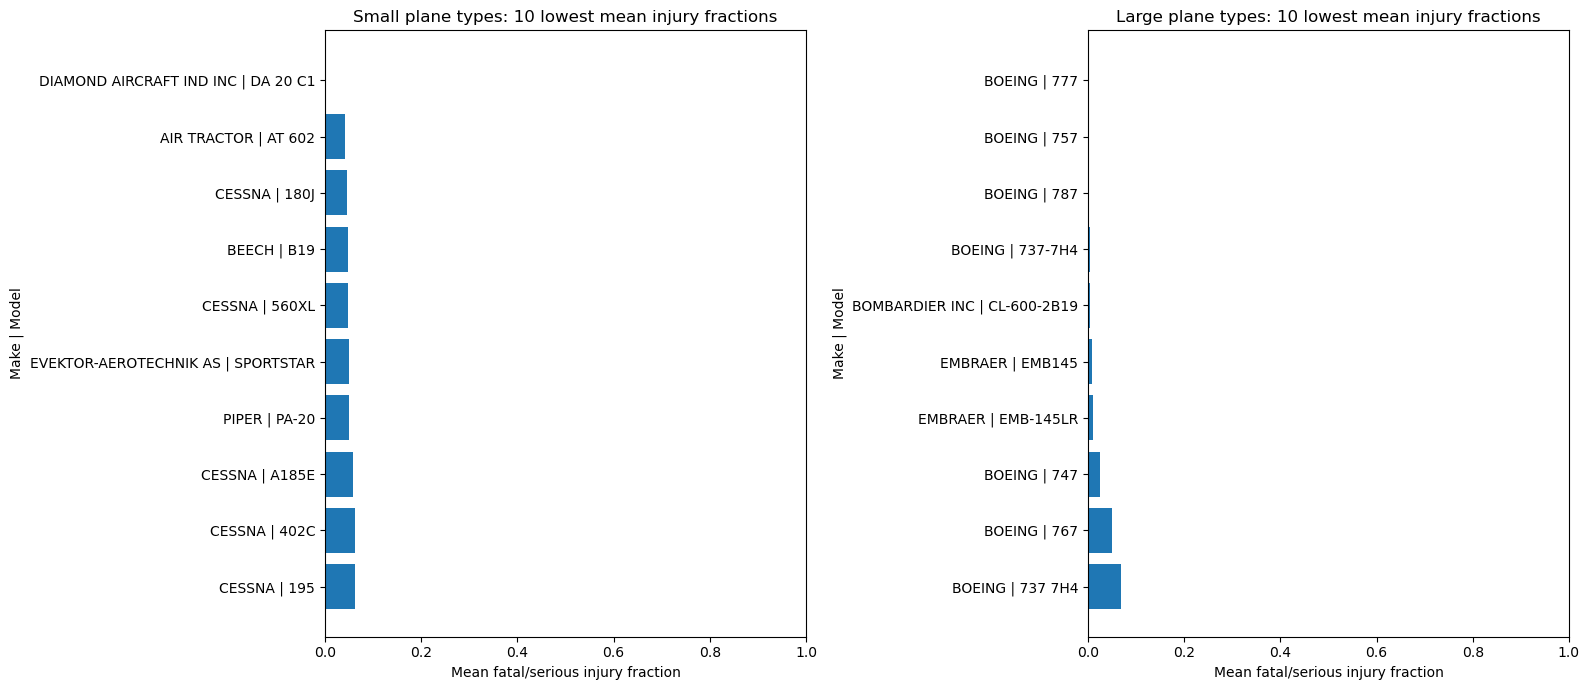

In [13]:
# Compare unique make/model types, using only types with at least 10 usable records.
plane_data = df.dropna(
    subset=["Plane.Type", "Plane.Size", "Fatal.Serious.Injury.Fraction"]
).copy()

plane_type_stats = (
    plane_data
    .groupby(["Plane.Size", "Plane.Type"])
    .agg(
        n=("Fatal.Serious.Injury.Fraction", "count"),
        mean_fraction=("Fatal.Serious.Injury.Fraction", "mean")
    )
    .reset_index()
)

eligible_planes = plane_type_stats.loc[plane_type_stats["n"] >= 10].copy()

small_planes_top10 = (
    eligible_planes.loc[eligible_planes["Plane.Size"].eq("Small")]
    .nsmallest(10, "mean_fraction")
)

large_planes_top10 = (
    eligible_planes.loc[eligible_planes["Plane.Size"].eq("Large")]
    .nsmallest(10, "mean_fraction")
)

print("Small plane types with at least 10 usable records:")
display(small_planes_top10[["Plane.Type", "n", "mean_fraction"]])

print("Large plane types with at least 10 usable records:")
display(large_planes_top10[["Plane.Type", "n", "mean_fraction"]])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, results, size in [
    (axes[0], small_planes_top10, "Small"),
    (axes[1], large_planes_top10, "Large")
]:
    if results.empty:
        ax.set_title(f"{size}: no plane types meet n >= 10")
        ax.set_axis_off()
        continue

    ax.barh(results["Plane.Type"], results["mean_fraction"])
    ax.set_title(f"{size} plane types: 10 lowest mean injury fractions")
    ax.set_xlabel("Mean fatal/serious injury fraction")
    ax.set_ylabel("Make | Model")
    ax.set_xlim(0, 1)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions


Results by Weather.Condition (groups with at least 50 records per measure):


,injury_n,mean_injury_fraction,damage_n,destroyed_fraction
Weather.Condition,,,,
IMC,905,0.636407,999,0.371371
VMC,14304,0.270953,16723,0.076601


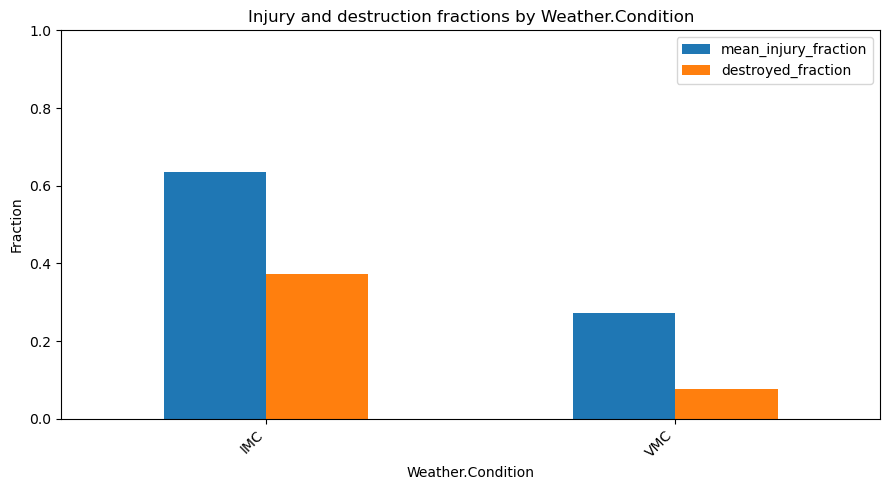


Results by Number.of.Engines (groups with at least 50 records per measure):


,injury_n,mean_injury_fraction,damage_n,destroyed_fraction
Number.of.Engines,,,,
1.0,13279.0,0.300716,15603,0.081395
2.0,2461.0,0.282401,2455,0.171079
4.0,56.0,0.159694,66,0.136364


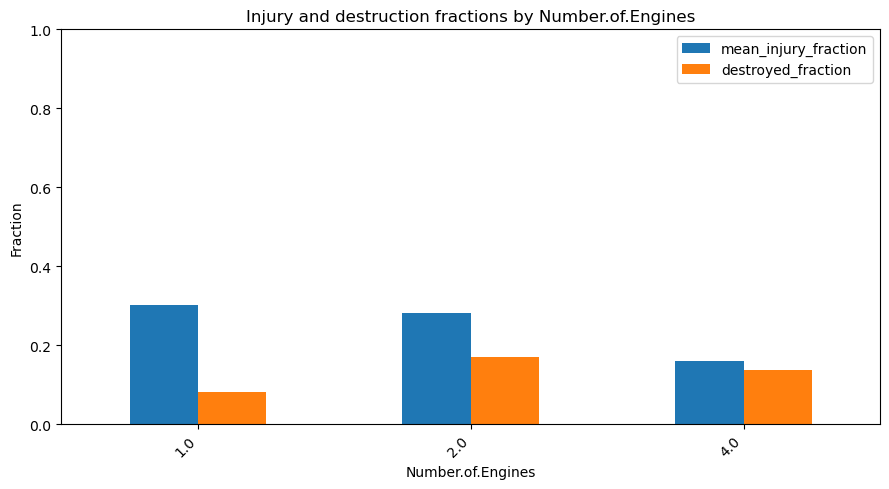

In [14]:
# Compare injury and destruction fractions across weather and engine-count groups.
# Each metric uses its own records with known values.

factor_data = df.copy()

factor_data["Aircraft.Destroyed.Numeric"] = (
    factor_data["Aircraft.Destroyed"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"true": 1.0, "false": 0.0})
)

for factor in ["Weather.Condition", "Number.of.Engines"]:
    injury_stats = (
        factor_data.dropna(subset=[factor, "Fatal.Serious.Injury.Fraction"])
        .groupby(factor)
        .agg(
            injury_n=("Fatal.Serious.Injury.Fraction", "count"),
            mean_injury_fraction=("Fatal.Serious.Injury.Fraction", "mean")
        )
    )

    destruction_stats = (
        factor_data.dropna(subset=[factor, "Aircraft.Destroyed.Numeric"])
        .groupby(factor)
        .agg(
            damage_n=("Aircraft.Destroyed.Numeric", "count"),
            destroyed_fraction=("Aircraft.Destroyed.Numeric", "mean")
        )
    )

    results = injury_stats.join(destruction_stats, how="outer")

    print(f"\nResults by {factor} (groups with at least 50 records per measure):")
    display(results.loc[
        (results["injury_n"] >= 50) | (results["damage_n"] >= 50)
    ].sort_index())

    plot_results = results.loc[
        (results["injury_n"] >= 50) & (results["damage_n"] >= 50)
    ].copy()

    if not plot_results.empty:
        plot_results[["mean_injury_fraction", "destroyed_fraction"]].plot(
            kind="bar",
            figsize=(9, 5),
            ylim=(0, 1),
            title=f"Injury and destruction fractions by {factor}"
        )
        plt.ylabel("Fraction")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [ ]:
### Discussion of Specific Airplane Types

# For small plane types, the Diamond Aircraft DA 20 C1 had the lowest mean fatal/serious injury fraction in the displayed results: 0.000 across 11 usable records. The Air Tractor AT 602 followed at 0.042 across 12 records, and the Cessna 180J at 0.045 across 22 records.

# For large plane types, the Boeing 777 had the lowest displayed mean fraction at 0.001 across 31 usable records. The Boeing 757 was 0.002 across 17 records, and the Boeing 787 was 0.003 across 11 records.

# These are the lowest averages among plane types with at least 10 usable accident records, but several sample sizes are small. Treat them as preliminary comparisons, not definitive safety rankings. The fractions describe fatal/serious injuries among reported occupants in accident records; they do not estimate risk per flight, and reported occupants may include crew. The small/large classification uses reported occupants in each record, not aircraft seating capacity.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.


Results by Weather.Condition:


,injury_n,mean_injury_fraction,damage_n,destroyed_fraction
Weather.Condition,,,,
IMC,905,0.636407,999,0.371371
VMC,14304,0.270953,16723,0.076601


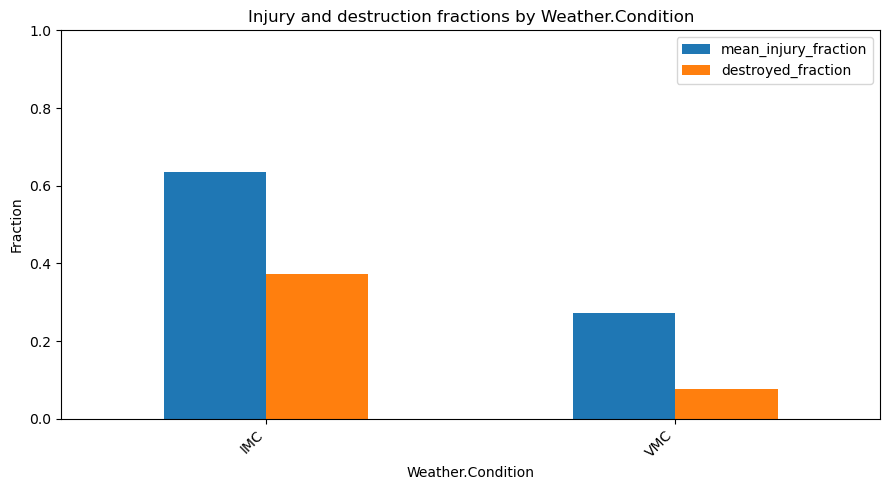


Results by Number.of.Engines:


,injury_n,mean_injury_fraction,damage_n,destroyed_fraction
Number.of.Engines,,,,
1.0,13279.0,0.300716,15603,0.081395
2.0,2461.0,0.282401,2455,0.171079
4.0,56.0,0.159694,66,0.136364


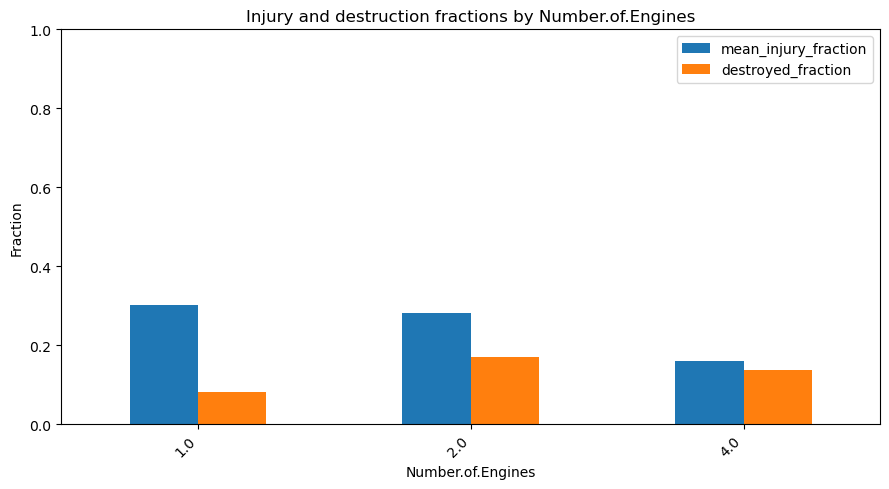

In [15]:
factor_data = df.copy()

# Convert the destroyed flag to numbers so its mean gives the destruction fraction.
factor_data["Aircraft.Destroyed.Numeric"] = (
    factor_data["Aircraft.Destroyed"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"true": 1.0, "false": 0.0})
)

for factor in ["Weather.Condition", "Number.of.Engines"]:
    injury_stats = (
        factor_data.dropna(
            subset=[factor, "Fatal.Serious.Injury.Fraction"]
        )
        .groupby(factor)
        .agg(
            injury_n=("Fatal.Serious.Injury.Fraction", "count"),
            mean_injury_fraction=("Fatal.Serious.Injury.Fraction", "mean")
        )
    )

    destruction_stats = (
        factor_data.dropna(
            subset=[factor, "Aircraft.Destroyed.Numeric"]
        )
        .groupby(factor)
        .agg(
            damage_n=("Aircraft.Destroyed.Numeric", "count"),
            destroyed_fraction=("Aircraft.Destroyed.Numeric", "mean")
        )
    )

    results = injury_stats.join(destruction_stats, how="outer")

    print(f"\nResults by {factor}:")
    display(results.loc[
        (results["injury_n"] >= 50) | (results["damage_n"] >= 50)
    ].sort_index())

    plot_results = results.loc[
        (results["injury_n"] >= 50) & (results["damage_n"] >= 50)
    ]

    if not plot_results.empty:
        plot_results[
            ["mean_injury_fraction", "destroyed_fraction"]
        ].plot(
            kind="bar",
            figsize=(9, 5),
            ylim=(0, 1),
            title=f"Injury and destruction fractions by {factor}"
        )
        plt.ylabel("Fraction")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

In [ ]:
### Weather condition

# Among accident records with usable injury data, the mean fatal/serious injury fraction was higher in IMC (0.636; 905 records) than in VMC (0.271; 14,304 records). The recorded destruction fraction was also higher in IMC (0.371; 999 records) than in VMC (0.077; 16,723 records). This suggests that instrument meteorological conditions are associated with worse outcomes in these accident records. It does not show that weather caused the difference; accident circumstances and other factors may differ between groups.

### Number of engines

# Single-engine records had a mean fatal/serious injury fraction of 0.301 (13,279 records) and destruction fraction of 0.081 (15,603 records). Two-engine records had a slightly lower mean injury fraction of 0.282 (2,461 records), but a higher destruction fraction of 0.171 (2,455 records). Four-engine records had lower observed fractions (injury 0.160 across 56 records; destruction 0.136 across 66 records), but this group is much smaller and should be interpreted cautiously.

# These are comparisons among accident records with known values, not safety rates per flight. The groups may differ in aircraft type, operation, accident severity, and reporting completeness, so these results show association rather than causation.